# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_:
- _Student No._: 20XX-XXXXX
- _Section_: fill in

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

**Figure 1. Synthetic data interpolation.** Insert a figure comparing the sampled sine data with the linear, nearest, quadratic, and cubic interpolations.

**Figure 2. Real-world data reconstruction.** Insert the four reconstruction plots for sampling levels of 50%, 30%, 10%, and 5%.

### Report discussion

**Interpolator comparison:** Discuss how the interpolation methods differ and which reproduces the underlying function most accurately for the synthetic data.

**Sampling-level comparison:** Discuss how reconstruction quality changes as the number of sampled data points decreases. Mention limitations and any visible artifacts.

### Other comments
- EDIT ME
- A self-reflection can be placed here. This portion is not graded.

---
## Section 2: Code

In [68]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path
from scipy.interpolate import interp1d 
from scipy.interpolate import CubicSpline
rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

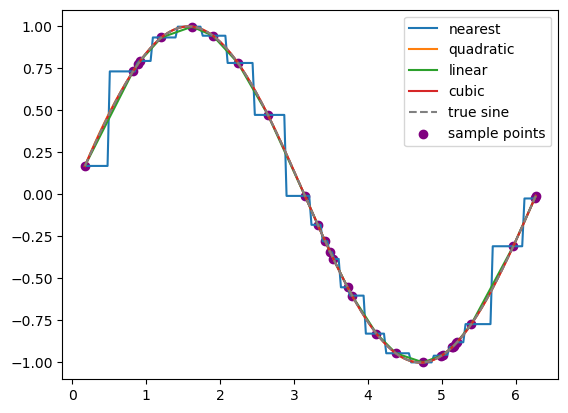

In [81]:
# code here

xRand = np.sort(np.random.uniform(0,2*np.pi,30))
randSin = np.sin(xRand)

linear = interp1d(xRand, randSin, kind='linear')
nearest = interp1d(xRand, randSin, kind= 'nearest')
cubic = CubicSpline(xRand, randSin)
quadratic = interp1d(xRand, randSin, kind = 'quadratic')

xGrid = np.linspace(xRand.min(), xRand.max(), 200)

yl = linear(xGrid)
yn = nearest(xGrid)
yc = cubic(xGrid)
yq = quadratic(xGrid)

sinTrue = np.sin(xGrid)




plt.plot(xGrid, yn, label = 'nearest')
plt.plot(xGrid, yq, label = 'quadratic')
plt.plot(xGrid, yl, label = 'linear')
plt.plot(xGrid, yc, label = 'cubic')


plt.plot(xGrid, sinTrue, '--', color = 'gray', label = 'true sine')

plt.scatter(xRand, randSin, color = 'purple', label = 'sample points')
plt.legend()



### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [82]:
!wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt




In [84]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

data = np.loadtxt('dow.txt',delimiter = ',', dtype = float,skiprows = 0)

print(data)

[12121.71 12136.44 12226.73 ... 11499.25 11491.91 11478.13]


### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

ValueError: x and y must be the same size

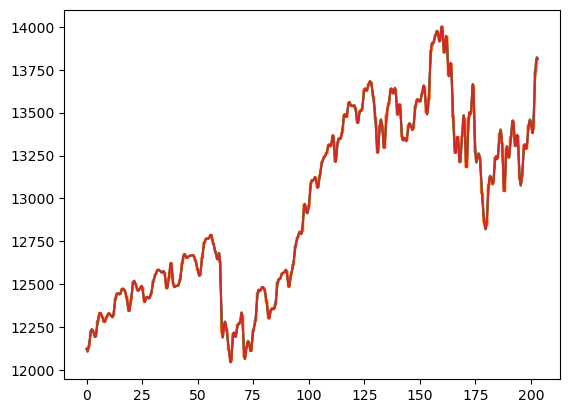

In [112]:
# code here

def samp(dat, frac):
    sample_size = int(len(dat)*frac)
    sampis = np.random.choice(len(data), size=sample_size, replace = False)

    sampled_data = dat[sampis]
    return sampled_data

def interDat(datum,interp):

    xIndex = np.arange(len(datum))
    xFine = np.linspace(0, len(interp) -1, 2000)

    iLinear = interp1d(xIndex, datum, kind = 'linear')
    iNearest = interp1d(xIndex, datum, kind = 'nearest')
    iCubic = CubicSpline(xIndex, datum)
    iQuadratic = interp1d(xIndex, datum, kind = 'quadratic')

    dl = iLinear(xFine)
    dn = iNearest(xFine)
    dc = iCubic(xFine)
    dq = iQuadratic(xFine)

    plt.plot(xFine, dl)
    plt.plot(xFine, dn)
    plt.plot(xFine, dc)
    plt.plot(xFine, dq)
    plt.scatter(xIndex, interp)


argh = samp(data, 0.2)

yomama = interDat(data, argh)


    



    



### Problem  code summary


Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---